In [1]:
import os
import torch
import torchvision
import torch.nn as nn
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Используем устройство {device}, Версия pytorch {torch.__version__}')

Используем устройство cuda, Версия pytorch 2.14.1+cu130


Загружаем датасет

In [2]:
from PIL import Image
from torch.utils.data import Dataset

root = "/workspace/datasets/oxford_pets"

train_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((128, 128)),
    v2.RandomHorizontalFlip(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((128, 128)),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class Pets(Dataset):
    def __init__(self, root, split, transform):
        self.root = root
        self.transform = transform
        with open(f"{root}/annotations/{split}.txt") as f:
            self.rows = [line.split() for line in f]

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        name, label, *_ = self.rows[idx]
        image = Image.open(f"{self.root}/images/{name}.jpg").convert("RGB")
        return self.transform(image), int(label) - 1

train_dataset = Pets(root, "trainval", transform=train_transform)
test_dataset = Pets(root, "test", transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(len(train_dataset), len(test_dataset))  # 3680, 3669

3680 3669


Взглянем на датасет

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8431373..1.977691].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8956583..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8952821..1.5419612].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0151556..2.5179958].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.605142].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0836544..2.326275].


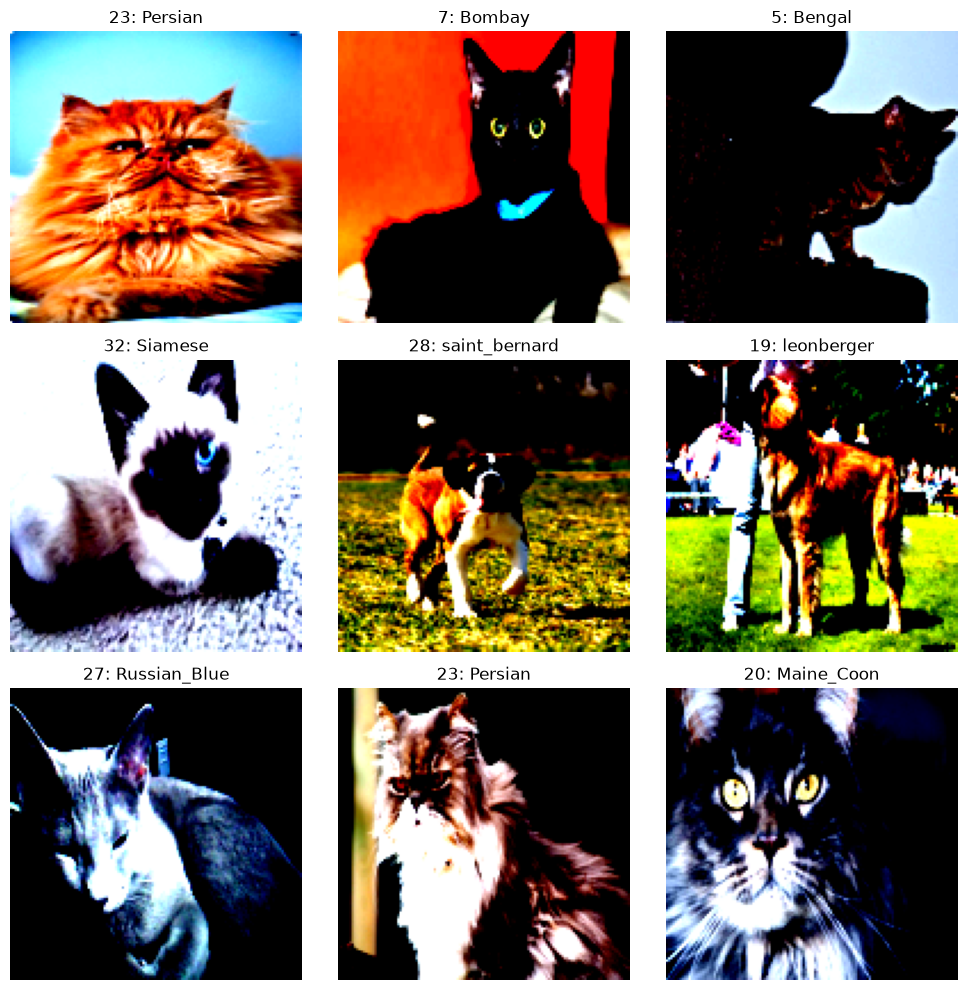

In [3]:
import matplotlib.pyplot as plt

names = {
    int(row[1]) - 1: row[0].rsplit("_", 1)[0]
    for row in train_dataset.rows
}

figure = plt.figure(figsize=(10, 10))

for i in range(1, 10):
    sample_idx = torch.randint(len(train_dataset), (1,)).item()
    img, label = train_dataset[sample_idx]

    figure.add_subplot(3, 3, i)
    plt.title(f"{label}: {names[label]}")
    plt.axis("off")
    plt.imshow(img.permute(1, 2, 0))

plt.tight_layout()
plt.show()

In [4]:
cpu_count = os.cpu_count() #my is 12, but this must be threads
num_workers = min(cpu_count, 6) if cpu_count else 0
print(cpu_count)

12


In [5]:
train_dataloader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=num_workers, pin_memory=True)
test_dataloader = DataLoader(test_dataset, batch_size=256, shuffle=False, num_workers=num_workers, pin_memory=True)

In [6]:
images, labels = next(iter(test_dataloader))
print (images.shape, labels.shape)

torch.Size([256, 3, 128, 128]) torch.Size([256])


Импортируем обученные веса сетей

In [7]:
from torchvision.models import resnet18, ResNet18_Weights, vgg19_bn, vgg16_bn, VGG19_BN_Weights, VGG16_BN_Weights

In [8]:
weights = ResNet18_Weights.DEFAULT
custom_weights_dir = "./weights/"
state_dict = weights.get_state_dict(progress=True, model_dir=custom_weights_dir)

In [9]:
weights2 = VGG16_BN_Weights.DEFAULT
custom_weights_dir = "./weights/"
state_dict2 = weights2.get_state_dict(progress=True, model_dir=custom_weights_dir)

In [10]:
weights3 = VGG19_BN_Weights.DEFAULT
custom_weights_dir = "./weights/"
state_dict3 = weights3.get_state_dict(progress=True, model_dir=custom_weights_dir)

Замораживаем слои

In [11]:
resnet18 = torchvision.models.resnet18()
vgg16 = vgg16_bn()
vgg19 = vgg19_bn()

resnet18.load_state_dict(state_dict)
vgg16.load_state_dict(state_dict2)
vgg19.load_state_dict(state_dict3)

for param in resnet18.parameters():
    param.requires_grad = False

for param in vgg16.parameters():
    param.requires_grad = False

for param in vgg19.parameters():
    param.requires_grad = False



Меняем классификационную голову под наши классы

In [12]:
name, layer = list(resnet18.named_modules())[-1]
print('resnet: ', name, layer)

name, layer = list(vgg16.named_modules())[-1]
print('vgg16: ', name, layer)

name, layer = list(vgg19.named_modules())[-1]
print('vgg19: ', name, layer)

resnet:  fc Linear(in_features=512, out_features=1000, bias=True)
vgg16:  classifier.6 Linear(in_features=4096, out_features=1000, bias=True)
vgg19:  classifier.6 Linear(in_features=4096, out_features=1000, bias=True)


In [13]:
print('resnet ', resnet18.fc.in_features)
print('vgg16 ', vgg16.classifier[6].in_features)
print('vgg19 ', vgg19.classifier[6].in_features)

resnet  512
vgg16  4096
vgg19  4096


In [14]:
resnet18.fc = nn.Linear(512, 37)
vgg16.classifier[6] = nn.Linear(4096, 37)
vgg19.classifier[6] = nn.Linear(4096, 37)
resnet18.to(device)
vgg16.to(device)
vgg19.to(device)

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [15]:
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, resnet18.parameters()), lr=1e-3)
optimizer2 = torch.optim.AdamW(filter(lambda p: p.requires_grad, vgg16.parameters()), lr=1e-3)
optimizer3 = torch.optim.AdamW(filter(lambda p: p.requires_grad, vgg19.parameters()), lr=1e-3)

In [16]:
print("Параметры на обучение:")
for name, param in resnet18.named_parameters():
    if param.requires_grad:
        print(f"-> {name}: {param.shape}")

Параметры на обучение:
-> fc.weight: torch.Size([37, 512])
-> fc.bias: torch.Size([37])


In [17]:
def train_epoch(model, train_loader, loss_criterion, optimizer, device):
    epoch_loss = 0.0
    total = 0
    model.train()
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        output = model(X)
        loss = loss_criterion(output, y)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * y.size(0)
        total += y.size(0)
    return epoch_loss / total


def eval(model, test_loader, loss_criterion, device):
    epoch_loss = 0.0
    correct = 0
    total = 0
    model.eval()
    with torch.no_grad():
        for X, y in test_loader:
            X, y = X.to(device), y.to(device)
            output = model(X)
            loss = loss_criterion(output, y)

            epoch_loss += loss.item() * y.size(0)
            correct += (output.argmax(dim=1) == y).sum().item()
            total += y.size(0)
    return epoch_loss / total, correct / total


Обучаем модели

In [18]:
epochs = 30

for epoch in range(epochs):
    train_loss = train_epoch(resnet18, train_dataloader, loss, optimizer, device)
    test_loss, acc = eval(resnet18, test_dataloader, loss, device)

    print(f'Эпоха {epoch}: train loss = {train_loss}, test_loss = {test_loss}, accuracy = {acc}')

Эпоха 0: train loss = 2.914887403405231, test_loss = 2.0463212356803915, accuracy = 0.49304987735077677
Эпоха 1: train loss = 1.7410181719323863, test_loss = 1.554961663690891, accuracy = 0.6116107931316435
Эпоха 2: train loss = 1.33687816599141, test_loss = 1.3535899027520026, accuracy = 0.6380485145816299
Эпоха 3: train loss = 1.147591247247613, test_loss = 1.257230433497581, accuracy = 0.6568547288089398
Эпоха 4: train loss = 1.0094168346861134, test_loss = 1.1875142866273964, accuracy = 0.6680294358135732
Эпоха 5: train loss = 0.9187913438548212, test_loss = 1.156743687467635, accuracy = 0.6691196511310984
Эпоха 6: train loss = 0.8564753822658373, test_loss = 1.127569383839295, accuracy = 0.6751158353774871
Эпоха 7: train loss = 0.7926790714263916, test_loss = 1.1028048994106439, accuracy = 0.6819296811120196
Эпоха 8: train loss = 0.7515279521112856, test_loss = 1.1012258581161238, accuracy = 0.6751158353774871
Эпоха 9: train loss = 0.705159558420596, test_loss = 1.0778912642113225

In [19]:
for epoch in range(epochs):
    train_loss = train_epoch(vgg16, train_dataloader, loss, optimizer2, device)
    test_loss, acc = eval(vgg16, test_dataloader, loss, device)

    print(f'VGG16, эпоха {epoch}: train loss = {train_loss}, test_loss = {test_loss}, accuracy = {acc}')

VGG16, эпоха 0: train loss = 1.4848930291507556, test_loss = 0.7033736954741922, accuracy = 0.7846824747887707


VGG16, эпоха 1: train loss = 0.6177296892456386, test_loss = 0.6454287802744184, accuracy = 0.7966748432815481


VGG16, эпоха 2: train loss = 0.5054202463315881, test_loss = 0.6500441275311608, accuracy = 0.7939493049877351


VGG16, эпоха 3: train loss = 0.43472787582356, test_loss = 0.6263843672042908, accuracy = 0.7996729354047425


VGG16, эпоха 4: train loss = 0.39354588959528053, test_loss = 0.628642184926366, accuracy = 0.7966748432815481


...

VGG16, эпоха 25: train loss = 0.12805724260599716, test_loss = 0.6937144526906674, accuracy = 0.7996729354047425


VGG16, эпоха 26: train loss = 0.12805161210505858, test_loss = 0.7081401540297974, accuracy = 0.7939493049877351


VGG16, эпоха 27: train loss = 0.12468058784370838, test_loss = 0.7022897700346858, accuracy = 0.8004905968928864


VGG16, эпоха 28: train loss = 0.12582902986070385, test_loss = 0.7227080013145053, accuracy = 0.8002180430635051


VGG16, эпоха 29: train loss = 0.12268120089302892, test_loss = 0.7131426119575321, accuracy = 0.7977650585990733


In [20]:
for epoch in range(epochs):
    train_loss = train_epoch(vgg19, train_dataloader, loss, optimizer3, device)
    test_loss, acc = eval(vgg19, test_dataloader, loss, device)

    print(f'VGG19, эпоха {epoch}: train loss = {train_loss}, test_loss = {test_loss}, accuracy = {acc}')

VGG19, эпоха 0: train loss = 1.4433582850124524, test_loss = 0.72291485167193, accuracy = 0.7691469065140365


VGG19, эпоха 1: train loss = 0.652823837943699, test_loss = 0.6997449316082355, accuracy = 0.7748705369310439


VGG19, эпоха 2: train loss = 0.5423383883807971, test_loss = 0.6709136720914287, accuracy = 0.7874080130825838


VGG19, эпоха 3: train loss = 0.4577594383903172, test_loss = 0.6697922281882327, accuracy = 0.7874080130825838


VGG19, эпоха 4: train loss = 0.4154440488504327, test_loss = 0.6666125832412378, accuracy = 0.7879531207413464


...

VGG19, эпоха 25: train loss = 0.15575687600218732, test_loss = 0.7495840527147712, accuracy = 0.7887707822294904


VGG19, эпоха 26: train loss = 0.1397499537338381, test_loss = 0.7458101805694488, accuracy = 0.7936767511583538


VGG19, эпоха 27: train loss = 0.1407583005402399, test_loss = 0.7538205894016381, accuracy = 0.7901335513763968


VGG19, эпоха 28: train loss = 0.14027396557123764, test_loss = 0.7666810867360127, accuracy = 0.7890433360588717


VGG19, эпоха 29: train loss = 0.13148877037608106, test_loss = 0.7734541725027168, accuracy = 0.791223766693922


Считаем метрики

ResNet18
Top-1 accuracy: 67.51%
Top-3 accuracy: 86.15%
Top-5 accuracy: 91.31%


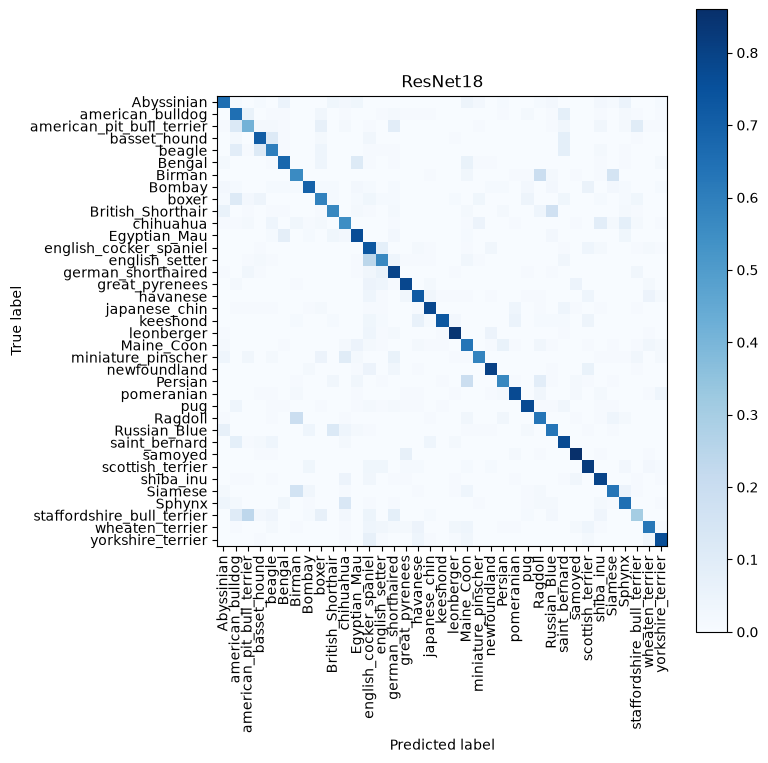

VGG16
Top-1 accuracy: 79.78%
Top-3 accuracy: 93.81%
Top-5 accuracy: 96.59%


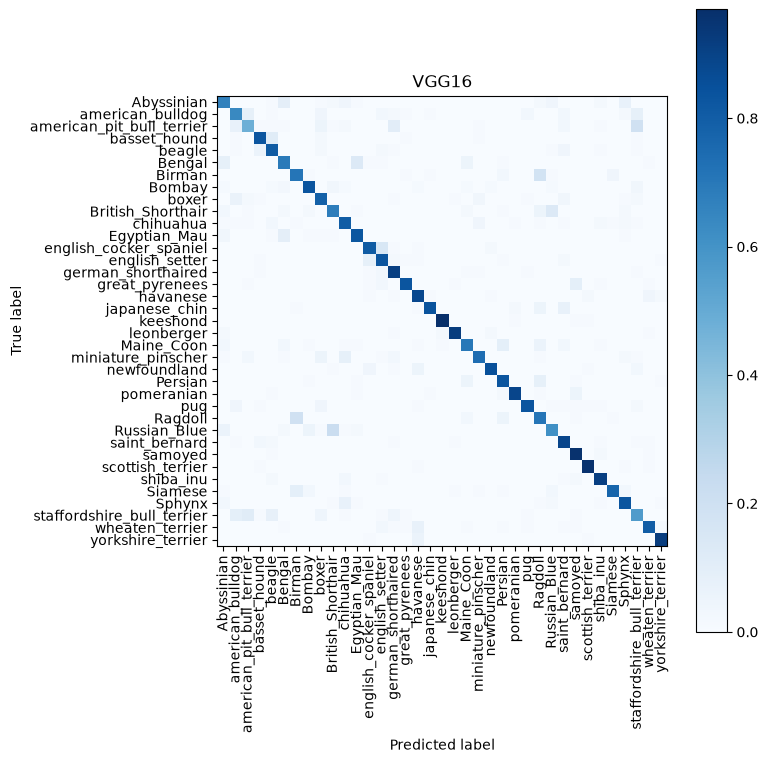

VGG19
Top-1 accuracy: 79.12%
Top-3 accuracy: 93.43%
Top-5 accuracy: 96.43%


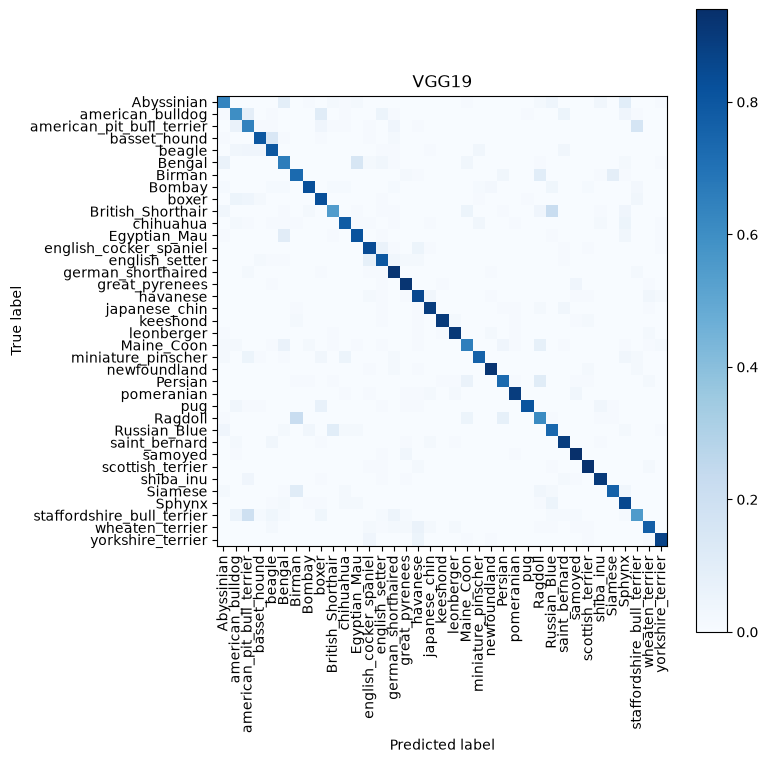

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

class_names = [names[i] for i in range(len(names))]
metrics_results = {}

for model_name, model in [('ResNet18', resnet18), ('VGG16', vgg16), ('VGG19', vgg19)]:
    correct1 = correct3 = correct5 = total = 0
    y_true, y_pred = [], []
    model.eval()

    with torch.no_grad():
        for X, y in test_dataloader:
            y = y.to(device)
            top5 = model(X.to(device)).topk(5, dim=1).indices
            matches = top5 == y[:, None]

            correct1 += matches[:, :1].any(dim=1).sum().item()
            correct3 += matches[:, :3].any(dim=1).sum().item()
            correct5 += matches.any(dim=1).sum().item()
            total += y.size(0)
            y_true.extend(y.cpu().tolist())
            y_pred.extend(top5[:, 0].cpu().tolist())

    cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)), normalize='true')
    metrics_results[model_name] = {
        'top1': correct1 / total,
        'top3': correct3 / total,
        'top5': correct5 / total,
        'confusion_matrix': cm,
    }

    print(model_name)
    print(f'Top-1 accuracy: {correct1 / total:.2%}')
    print(f'Top-3 accuracy: {correct3 / total:.2%}')
    print(f'Top-5 accuracy: {correct5 / total:.2%}')

    fig, ax = plt.subplots(figsize=(8, 8))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
        include_values=False, xticks_rotation=90, cmap='Blues', ax=ax,
    )
    ax.set_title(model_name)
    plt.tight_layout()
    plt.show()